# Liquidity Absorption V2 — CVD absorption filter, 18:00-ET volume-profile targets (LVN → next HVN), engine stop

Pre-registration: `discussions/Liquidity_Absorption/025_claude_v2_cvd_profile_preregistration.md`. Code: `src/data_engineering/modeling/liquidity_absorption_v2.py`.

**Reuses the EXT run:** its A02/A02b signals (`notebooks/Liquidity_Absorption/EXT/`) and venue inputs (`DERIBIT_DATA_ROOT\la_ext_venue`). Run EXT first.

**Primary:** CVD filter on, TRAIL_1M (breakeven at +1R, then 1-minute swing trail), profile target, VD18 risk stop, Deribit fees, the LA 024 gate.

**Also reported:** FIXED / BREAKEVEN, the same without the CVD filter, the CUT15 variants, and Kelly fractions on net R multiples.

`LAV2_SYNTHETIC=1` for a smoke run.

In [1]:
from pathlib import Path
import json, os, sys, tempfile, time, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from dotenv import load_dotenv
warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 250)
load_dotenv()
REPO = Path.cwd().resolve()
while REPO != REPO.parent and not (REPO / 'src' / 'data_engineering').exists():
    REPO = REPO.parent
sys.path.insert(0, str(REPO)); sys.path.insert(0, str(REPO / 'src'))
from src.data_engineering.modeling import liquidity_absorption_v2 as v2, liquidity_absorption_extended as ex
SYN = os.getenv('LAV2_SYNTHETIC', '').strip() == '1'
if SYN:
    TMP = Path(tempfile.mkdtemp(prefix='lav2_')); ROOT = TMP / 'venue'; EXT = TMP / 'EXT'; OUT = TMP / 'V2'
    days = [str(x.date()) for x in pd.date_range('2026-06-01', periods=14, freq='D')]
    ex.synthetic_history(TMP / 'history', days, seed=6); ex.prepare_venue_root(TMP / 'history', ROOT, ex.Spec(start='2026-06-01'), log=None)
    ex.stage_a02(ROOT, EXT, ex.Spec(start='2026-06-04')); ex.stage_a02b(ROOT, EXT)
else:
    DATA = Path(os.environ['DERIBIT_DATA_ROOT']).expanduser().resolve()
    ROOT = DATA / 'la_ext_venue'; EXT = REPO / 'notebooks' / 'Liquidity_Absorption' / 'EXT'; OUT = REPO / 'notebooks' / 'Liquidity_Absorption' / 'V2'
OUT.mkdir(parents=True, exist_ok=True)
print(v2.VERSION, '| synthetic' if SYN else '', '| EXT', EXT, '| out', OUT)
print(json.dumps(v2.registration(), indent=1))

LA-V2-0.1.0  | EXT D:\Projects\deribit_market_data\notebooks\Liquidity_Absorption\EXT | out D:\Projects\deribit_market_data\notebooks\Liquidity_Absorption\V2
{
 "version": "LA-V2-0.1.0",
 "bin_bp": 5.0,
 "smooth_bins": 3,
 "min_session_min": 120,
 "lvn_frac": 0.2,
 "hvn_frac": 0.5,
 "min_target_bp": 10.0,
 "sigma_mult": 1.0,
 "cut_minutes": 15,
 "session_hour_ny": 18,
 "primary": "CVD filter ON, profile LVN->HVN target, VD18 risk stop, TRAIL_1M, no CUT15, Deribit fees",
 "gate": "as LA 024: mean net > 0 and one-sided 95% day-bootstrap lower bound > 0 in BTC/ETH x H1/H2 holdout"
}


## 1. Signals: CVD filter, session profile and LVN → HVN targets, VD18 sigma; simulation (6 variants per signal)

In [2]:
t0 = time.time()
RES = v2.run_v2(EXT, ROOT, REPO, OUT)
SIG = pd.read_csv(OUT / 'V2_signals.csv', low_memory=False)
print('signals', len(SIG), '| CVD absorption share', round(SIG.cvd_ok.mean(), 3), f'| {time.time()-t0:.0f}s')
display(SIG.groupby(['symbol', 'cvd_ok']).size().unstack(fill_value=0))
display(SIG.v2_target_source.value_counts())
ok = SIG.v2_target.notna()
SIG['target_bp'] = np.abs(SIG.v2_target / SIG.bar_close - 1) * 1e4
display(SIG.loc[ok, ['target_bp', 'sigma_bp_60', 'session_age_min']].describe().round(1))

signals 2564 | CVD absorption share 0.424 | 262s


cvd_ok,False,True
symbol,,
BTCUSDT,671,533
ETHUSDT,806,554


v2_target_source
NO_PROFILE_TARGET               1729
PROFILE_LVN_TO_HVN               664
NO_PROFILE_SESSION_TOO_YOUNG     170
NO_PROFILE                         1
Name: count, dtype: int64

,target_bp,sigma_bp_60,session_age_min
count,664.0,611.0,664.0
mean,122.6,58.3,870.9
std,83.4,21.7,342.2
min,12.7,16.6,123.0
25%,62.9,43.8,597.5
50%,99.8,54.6,924.0
75%,159.2,68.8,1150.5
max,583.8,181.4,1433.0


## 2. Verdict (primary) and all variants

In [3]:
T, DEC = v2.evaluate(OUT)
T.to_csv(OUT / 'V2_results_by_period.csv', index=False)
(OUT / 'V2_decision.json').write_text(json.dumps(DEC, indent=1, default=str)); print(json.dumps(DEC, indent=1, default=str))
display(T[T.cvd_filter & T.variant.eq('TRAIL_1M')].round(3))
display(T[T.period.eq('HOLDOUT') & T.symbol.eq('ALL')].sort_values(['cvd_filter', 'variant']).round(3))

{
 "version": "LA-V2-0.1.0",
 "primary": "CVD on, TRAIL_1M, profile target, Deribit fees",
 "cells": {
  "BTCUSDT_H1": false,
  "BTCUSDT_H2": false,
  "ETHUSDT_H1": false,
  "ETHUSDT_H2": false
 },
 "holdout_by_symbol_lo95_positive": {
  "BTCUSDT": false,
  "ETHUSDT": false
 },
 "verdict": "FAIL",
 "signals": 2564,
 "cvd_ok_share": 0.42394695787831516,
 "target_sources": {
  "NO_PROFILE_TARGET": 1729,
  "PROFILE_LVN_TO_HVN": 664,
  "NO_PROFILE_SESSION_TOO_YOUNG": 170,
  "NO_PROFILE": 1
 }
}


,cvd_filter,variant,symbol,period,closed,target,stop,timeout,cut15,win_rate_net,median_reward_to_risk,mean_gross_bp,gross_lo95,mean_net_bp,net_lo95,mean_net_R,kelly_f,kelly_log_growth
45,True,TRAIL_1M,BTCUSDT,H1,41,6,32,3,0,0.439,2.448,-5.563,-19.699,-17.341,-31.576,-0.282,0.0,0.0
46,True,TRAIL_1M,BTCUSDT,H2,52,6,43,3,0,0.404,1.664,-8.939,-20.060,-20.766,-31.925,-0.415,0.0,0.0
47,True,TRAIL_1M,BTCUSDT,INSAMPLE_JUL_SEP_2026,24,4,19,1,0,0.542,2.339,2.621,-10.288,-9.175,-22.102,-0.275,0.0,0.0
48,True,TRAIL_1M,ETHUSDT,H1,75,17,55,3,0,0.507,1.658,-1.649,-13.415,-13.385,-25.164,-0.241,0.0,0.0
49,True,TRAIL_1M,ETHUSDT,H2,60,13,43,4,0,0.400,1.912,-14.391,-27.268,-26.108,-39.054,-0.467,0.0,0.0
50,True,TRAIL_1M,ETHUSDT,INSAMPLE_JUL_SEP_2026,15,2,12,1,0,0.333,1.414,-14.513,-37.160,-26.307,-49.012,-0.471,0.0,0.0
51,True,TRAIL_1M,BTCUSDT,HOLDOUT,93,12,75,6,0,0.419,1.821,-7.450,-16.077,-19.256,-27.904,-0.356,0.0,0.0
52,True,TRAIL_1M,ETHUSDT,HOLDOUT,135,30,98,7,0,0.459,1.671,-7.312,-16.282,-19.040,-28.028,-0.341,0.0,0.0
53,True,TRAIL_1M,ALL,HOLDOUT,228,42,173,13,0,0.443,1.778,-7.368,-13.958,-19.128,-25.744,-0.347,0.0,0.0


,cvd_filter,variant,symbol,period,closed,target,stop,timeout,cut15,win_rate_net,median_reward_to_risk,mean_gross_bp,gross_lo95,mean_net_bp,net_lo95,mean_net_R,kelly_f,kelly_log_growth
62,False,BREAKEVEN,ALL,HOLDOUT,536,141,331,64,0,0.356,1.871,-1.135,-6.091,-12.753,-17.728,-0.244,0.0,0.0
71,False,CUT15_BREAKEVEN,ALL,HOLDOUT,537,99,183,39,216,0.244,1.868,-1.349,-5.615,-12.691,-16.966,-0.242,0.0,0.0
80,False,CUT15_FIXED,ALL,HOLDOUT,536,106,144,70,216,0.287,1.867,0.355,-4.291,-10.914,-15.572,-0.220,0.0,0.0
89,False,CUT15_TRAIL_1M,ALL,HOLDOUT,537,68,241,12,216,0.341,1.868,-0.659,-4.474,-12.108,-15.918,-0.233,0.0,0.0
98,False,FIXED,ALL,HOLDOUT,535,149,282,104,0,0.413,1.868,-0.389,-5.930,-11.917,-17.504,-0.237,0.0,0.0
107,False,TRAIL_1M,ALL,HOLDOUT,536,98,411,27,0,0.498,1.871,0.387,-4.198,-11.380,-15.977,-0.226,0.0,0.0
8,True,BREAKEVEN,ALL,HOLDOUT,228,55,143,30,0,0.338,1.778,-8.662,-15.495,-20.289,-27.182,-0.367,0.0,0.0
17,True,CUT15_BREAKEVEN,ALL,HOLDOUT,229,38,77,16,98,0.223,1.768,-7.106,-12.299,-18.443,-23.633,-0.333,0.0,0.0
26,True,CUT15_FIXED,ALL,HOLDOUT,229,40,61,30,98,0.253,1.768,-4.115,-10.686,-15.381,-22.019,-0.302,0.0,0.0
35,True,CUT15_TRAIL_1M,ALL,HOLDOUT,229,28,98,5,98,0.310,1.768,-4.924,-10.066,-16.354,-21.515,-0.298,0.0,0.0


## 3. Does the CVD filter separate outcomes? (holdout, closed trades, descriptive)

In [4]:
ev = pd.read_csv(OUT / 'V2_events.csv', low_memory=False); ev['net_deribit'] = ex.deribit_net(ev)
z = ev[ev.reason.isin(v2.CLOSED) & ev.v2_variant.eq('FIXED')].copy(); z['period'] = ex.period_label(z.signal_time_utc)
z = z[z.period != 'INSAMPLE_JUL_SEP_2026']
display(z.groupby(['symbol', 'cvd_ok']).agg(n=('net_deribit', 'size'), target_rate=('reason', lambda s: (s == 'TARGET').mean()),
        mean_gross=('gross_return_bp', 'mean'), mean_net=('net_deribit', 'mean'), median_rr=('reward_to_risk', 'median')).round(3))

n  target_rate  mean_gross  mean_net  median_rr
symbol  cvd_ok                                                   
BTCUSDT False   128        0.344      11.517     0.043      1.957
        True     93        0.215      -2.405   -13.959      1.821
ETHUSDT False   179        0.268      -1.469   -13.009      1.932
        True    135        0.274      -8.858   -20.401      1.671

## 4. Equity, primary variant (Deribit fees, 1 unit per trade, holdout and in-sample shaded)

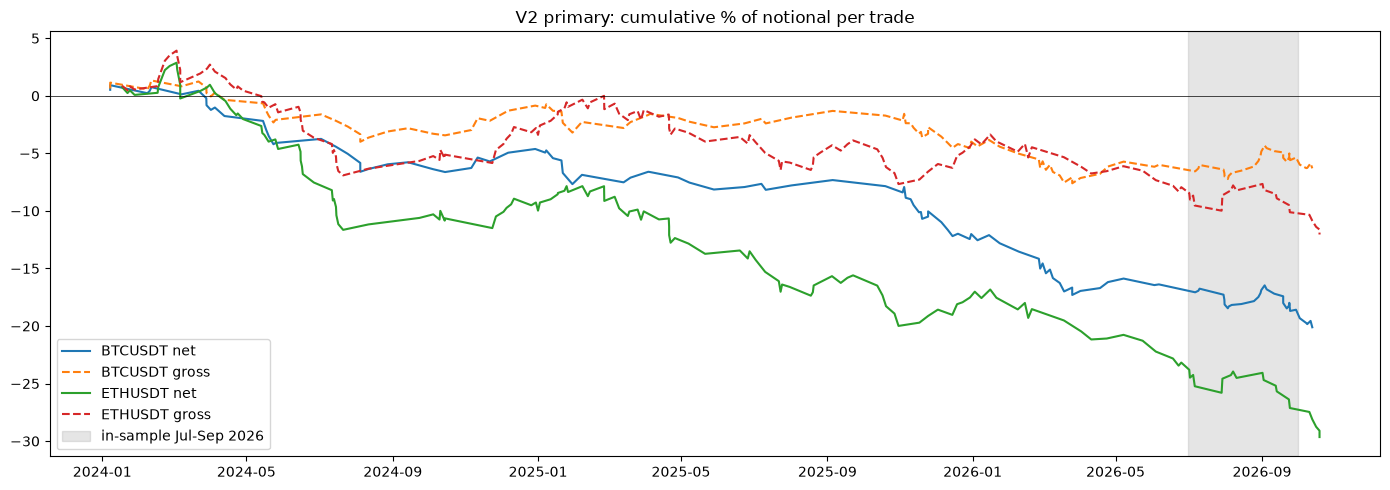

In [5]:
p = ev[ev.cvd_ok & ev.v2_variant.eq('TRAIL_1M') & ev.reason.isin(v2.CLOSED)].copy()
p['t'] = pd.to_datetime(p.exit_time_ms, unit='ms', utc=True); p = p.sort_values('t')
fig, ax = plt.subplots(figsize=(14, 5))
for s, g in p.groupby('symbol'):
    ax.plot(g.t, g.net_deribit.cumsum() / 100, label=f'{s} net'); ax.plot(g.t, g.gross_return_bp.cumsum() / 100, ls='--', label=f'{s} gross')
ax.axvspan(*ex.INSAMPLE, color='grey', alpha=.2, label='in-sample Jul-Sep 2026'); ax.axhline(0, c='k', lw=.5); ax.legend()
ax.set_title('V2 primary: cumulative % of notional per trade'); plt.tight_layout(); plt.savefig(OUT / 'V2_equity.png', dpi=110); plt.show()